In [ ]:
import pandas as pd

df = pd.read_csv("ecommerce_sales_ai_agent_dataset.csv")

df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Segment,Product,Category,Region,City,Quantity,Discount,Sales,Cost,Profit,Payment_Method
0,ORD00001,2024-04-12,CUST00021,New,Makeup Kit,Beauty,West,Ahmedabad,1,0.00,1905.46,990.84,914.62,Debit Card
1,ORD00002,2025-10-25,CUST00414,New,Dumbbells,Sports,West,Mumbai,1,0.05,2714.72,1743.14,971.58,Credit Card
2,ORD00003,2025-07-14,CUST00700,New,Smartwatch,Electronics,East,Patna,1,0.15,5210.96,4781.82,429.14,Credit Card
3,ORD00004,2025-05-19,CUST00167,New,Running Shoes,Fashion,North,Lucknow,4,0.10,12369.00,7971.13,4397.87,UPI
4,ORD00005,2024-12-05,CUST00776,New,Tablet,Electronics,South,Kochi,4,0.05,101213.20,83101.36,18111.84,UPI


In [ ]:
df.shape

(2508, 14)

In [ ]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Segment', 'Product',
       'Category', 'Region', 'City', 'Quantity', 'Discount', 'Sales', 'Cost',
       'Profit', 'Payment_Method'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2508 entries, 0 to 2507
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2508 non-null   object 
 1   Order_Date        2508 non-null   object 
 2   Customer_ID       2508 non-null   object 
 3   Customer_Segment  2508 non-null   object 
 4   Product           2508 non-null   object 
 5   Category          2508 non-null   object 
 6   Region            2508 non-null   object 
 7   City              2496 non-null   object 
 8   Quantity          2508 non-null   int64  
 9   Discount          2503 non-null   float64
 10  Sales             2508 non-null   float64
 11  Cost              2508 non-null   float64
 12  Profit            2508 non-null   float64
 13  Payment_Method    2500 non-null   object 
dtypes: float64(4), int64(1), object(9)
memory usage: 274.4+ KB


In [ ]:
df.describe()

,Quantity,Discount,Sales,Cost,Profit
count,2508.000000,2503.000000,2508.000000,2508.000000,2508.000000
mean,1.907097,0.094307,17147.391089,14008.410080,3138.980941
std,1.096347,0.068868,34140.034131,29033.946706,5788.727737
min,1.000000,0.000000,445.130000,289.330000,-4904.960000
25%,1.000000,0.050000,2754.447500,1796.077500,757.045000
50%,2.000000,0.100000,5571.430000,3838.760000,1448.225000
75%,3.000000,0.150000,14177.420000,11002.945000,2988.265000
max,5.000000,0.250000,338078.380000,271710.660000,74377.240000


In [ ]:
df.isnull().sum()

Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Segment     0
Product              0
Category             0
Region               0
City                12
Quantity             0
Discount             5
Sales                0
Cost                 0
Profit               0
Payment_Method       8
dtype: int64

In [ ]:



df.duplicated().sum()

np.int64(8)

In [ ]:
df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

Category
Electronics       32646150.80
Home & Kitchen     5798391.22
Fashion            2205127.46
Sports             1506630.06
Beauty              849357.31
Name: Sales, dtype: float64

In [ ]:
df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

Category
Electronics       4707808.87
Home & Kitchen    1541966.38
Fashion            779107.34
Sports             484435.65
Beauty             359245.96
Name: Profit, dtype: float64

In [ ]:
df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

Region
South      11463003.39
West        9545045.51
Central     7884853.45
North       7323152.54
East        6789601.96
Name: Sales, dtype: float64

In [ ]:
df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)

Product
Laptop            16386152.09
Smartphone         8646568.13
Tablet             5111665.70
Vacuum Cleaner     2084773.39
Smartwatch         1628988.94
Air Fryer          1036680.70
Coffee Maker       1018425.00
Headphones          872775.94
Cookware Set        845192.89
Mixer Grinder       813319.24
Name: Sales, dtype: float64

In [ ]:
df.groupby("Product")["Profit"].sum().sort_values(ascending=False).head(10)

Product
Laptop            2456497.46
Smartphone        1186115.06
Tablet             710337.87
Vacuum Cleaner     576825.34
Coffee Maker       266414.51
Air Fryer          263405.11
Smartwatch         239150.09
Cookware Set       223139.90
Running Shoes      222612.58
Jacket             218806.25
Name: Profit, dtype: float64

In [ ]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
monthly_sales = df.groupby(
    df["Order_Date"].dt.to_period("M")
)["Sales"].sum()

monthly_sales

Order_Date
2024-01    1721756.36
2024-02    1082837.03
2024-03    2936430.97
2024-04    1557033.41
2024-05    1628418.21
2024-06    1545948.31
2024-07    1343992.13
2024-08    1783441.84
2024-09    1300215.11
2024-10    1395425.15
2024-11    1287956.24
2024-12    2069274.00
2025-01    1572006.46
2025-02    1541789.47
2025-03    2118123.00
2025-04    1975938.98
2025-05    1305189.24
2025-06    2657733.36
2025-07    2072762.05
2025-08    2812382.82
2025-09    1799787.35
2025-10    1706585.72
2025-11    1849534.46
2025-12    1941095.18
Freq: M, Name: Sales, dtype: float64

In [ ]:
df.shape

(2508, 14)

In [ ]:

df = df.drop_duplicates()

In [ ]:

df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Segment     0
Product              0
Category             0
Region               0
City                12
Quantity             0
Discount             5
Sales                0
Cost                 0
Profit               0
Payment_Method       8
dtype: int64

In [ ]:
df["City"] = df["City"].fillna("Unknown")

In [ ]:
df["Discount"] = df["Discount"].fillna(df["Discount"].median())

In [ ]:
df["Payment_Method"] = df["Payment_Method"].fillna("Unknown")

In [ ]:
df.isnull().sum()

Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Segment    0
Product             0
Category            0
Region              0
City                0
Quantity            0
Discount            0
Sales               0
Cost                0
Profit              0
Payment_Method      0
dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2500 entries, 0 to 2499
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          2500 non-null   object        
 1   Order_Date        2500 non-null   datetime64[ns]
 2   Customer_ID       2500 non-null   object        
 3   Customer_Segment  2500 non-null   object        
 4   Product           2500 non-null   object        
 5   Category          2500 non-null   object        
 6   Region            2500 non-null   object        
 7   City              2500 non-null   object        
 8   Quantity          2500 non-null   int64         
 9   Discount          2500 non-null   float64       
 10  Sales             2500 non-null   float64       
 11  Cost              2500 non-null   float64       
 12  Profit            2500 non-null   float64       
 13  Payment_Method    2500 non-null   object        
dtypes: datetime64[ns](1), float64

In [ ]:
df.shape

(2500, 14)

In [ ]:
Q1_sales = df["Sales"].quantile(0.25)
Q3_sales = df["Sales"].quantile(0.75)

IQR_sales = Q3_sales - Q1_sales

upper_sales = Q3_sales + 1.5 * IQR_sales

sales_outliers = df[df["Sales"] > upper_sales]

len(sales_outliers)

317

In [ ]:
sales_outliers[["Order_ID", "Product", "Category", "Quantity", "Discount", "Sales", "Profit"]].head(10)

,Order_ID,Product,Category,Quantity,Discount,Sales,Profit
4,ORD00005,Tablet,Electronics,4,0.05,101213.20,18111.84
7,ORD00008,Laptop,Electronics,1,0.00,68280.80,15021.78
8,ORD00009,Smartphone,Electronics,3,0.10,83433.18,11124.42
33,ORD00034,Laptop,Electronics,1,0.05,73438.90,13141.70
45,ORD00046,Tablet,Electronics,3,0.15,52342.19,4310.53
50,ORD00051,Laptop,Electronics,1,0.15,58920.85,4852.31
74,ORD00075,Laptop,Electronics,1,0.20,54750.75,1368.77
87,ORD00088,Tablet,Electronics,2,0.10,33593.77,4479.17
89,ORD00090,Tablet,Electronics,2,0.00,54208.86,11925.95
97,ORD00098,Tablet,Electronics,2,0.15,44341.44,3651.65


In [ ]:
negative_profit = df[df["Profit"] < 0]

len(negative_profit)

31

In [ ]:
negative_profit[
    ["Order_ID", "Product", "Category", "Quantity",
     "Discount", "Sales", "Cost", "Profit"]
].head(10)

,Order_ID,Product,Category,Quantity,Discount,Sales,Cost,Profit
112,ORD00113,Headphones,Electronics,2,0.25,5572.73,5795.64,-222.91
124,ORD00125,Headphones,Electronics,5,0.25,13649.27,14195.24,-545.97
366,ORD00367,Tablet,Electronics,3,0.25,57846.84,60160.71,-2313.87
406,ORD00407,Headphones,Electronics,1,0.25,2820.61,2933.44,-112.82
410,ORD00411,Headphones,Electronics,3,0.25,8750.50,9100.52,-350.02
442,ORD00443,Smartwatch,Electronics,1,0.25,5699.58,5927.57,-227.98
455,ORD00456,Headphones,Electronics,2,0.25,4999.55,5199.53,-199.98
459,ORD00460,Smartphone,Electronics,2,0.25,39411.14,40987.59,-1576.45
494,ORD00495,Smartphone,Electronics,2,0.25,43710.71,45459.13,-1748.43
586,ORD00587,Tablet,Electronics,1,0.25,17731.72,18440.98,-709.27


In [ ]:
df[["Quantity", "Discount", "Sales", "Cost", "Profit"]].describe()

,Quantity,Discount,Sales,Cost,Profit
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1.906000,0.094360,17164.425028,14023.615580,3140.809388
std,1.096561,0.068848,34181.818265,29068.501455,5796.956364
min,1.000000,0.000000,445.130000,289.330000,-4904.960000
25%,1.000000,0.050000,2744.295000,1792.947500,756.240000
50%,2.000000,0.100000,5571.430000,3841.480000,1445.140000
75%,3.000000,0.150000,14177.420000,11002.945000,2988.265000
max,5.000000,0.250000,338078.380000,271710.660000,74377.240000


In [ ]:
df.dtypes

Order_ID                    object
Order_Date          datetime64[ns]
Customer_ID                 object
Customer_Segment            object
Product                     object
Category                    object
Region                      object
City                        object
Quantity                     int64
Discount                   float64
Sales                      float64
Cost                       float64
Profit                     float64
Payment_Method              object
dtype: object

In [ ]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [ ]:
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100

In [ ]:
df["Order_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

In [ ]:
df["Order_Year"] = df["Order_Date"].dt.year

In [ ]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", round(average_order_value, 2))
print("Overall Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 42911062.57
Total Profit: 7852023.47
Total Orders: 2500
Total Customers: 764
Average Order Value: 17164.43
Overall Profit Margin: 18.3 %


***Business Analysis***

**Category performance**

In [ ]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order_ID", "nunique"),
    Quantity=("Quantity", "sum")
).sort_values("Total_Sales", ascending=False)

category_analysis

,Total_Sales,Total_Profit,Orders,Quantity
Category,,,,
Electronics,32594343.64,4700901.25,702,1364
Home & Kitchen,5782066.15,1538509.31,549,1025
Fashion,2194786.59,775079.85,547,1040
Sports,1498600.85,482000.96,345,638
Beauty,841265.34,355532.10,357,698


**Regional performance**

In [ ]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order_ID", "nunique")
).sort_values("Total_Sales", ascending=False)

region_analysis

,Total_Sales,Total_Profit,Orders
Region,,,
South,11407371.19,2104851.83,611
West,9538671.83,1752994.75,626
Central,7864561.19,1375396.17,439
North,7317078.29,1391442.36,457
East,6783380.07,1227338.36,367


**Top 10 products**

In [ ]:
top_products = df.groupby("Product").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order_ID", "nunique")
).sort_values("Sales", ascending=False).head(10)

top_products

,Sales,Profit,Orders
Product,,,
Laptop,16334344.93,2449589.84,140
Smartphone,8646568.13,1186115.06,165
Tablet,5111665.70,710337.87,135
Vacuum Cleaner,2084773.39,576825.34,127
Smartwatch,1628988.94,239150.09,130
Air Fryer,1036680.70,263405.11,89
Coffee Maker,1018425.00,266414.51,110
Headphones,872775.94,115708.39,132
Cookware Set,828867.82,219682.83,120


In [ ]:
print("Top Category by Sales:")
print(category_analysis["Total_Sales"].idxmax())

print("\nTop Category by Profit:")
print(category_analysis["Total_Profit"].idxmax())

print("\nLowest Category by Profit:")
print(category_analysis["Total_Profit"].idxmin())

print("\nBest Region by Sales:")
print(region_analysis["Total_Sales"].idxmax())

print("\nTop Product by Sales:")
print(top_products["Sales"].idxmax())

Top Category by Sales:
Electronics

Top Category by Profit:
Electronics

Lowest Category by Profit:
Beauty

Best Region by Sales:
South

Top Product by Sales:
Laptop


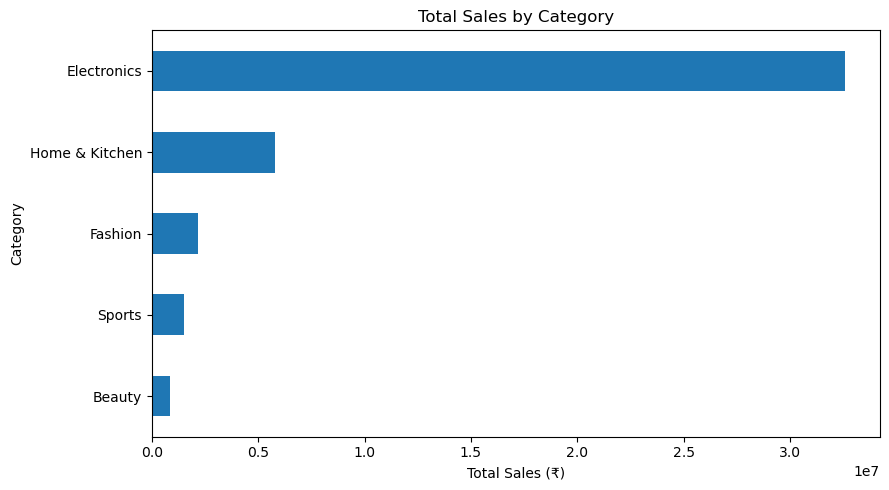

In [ ]:
import matplotlib.pyplot as plt

category_analysis["Total_Sales"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Total Sales by Category"
)

plt.xlabel("Total Sales (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

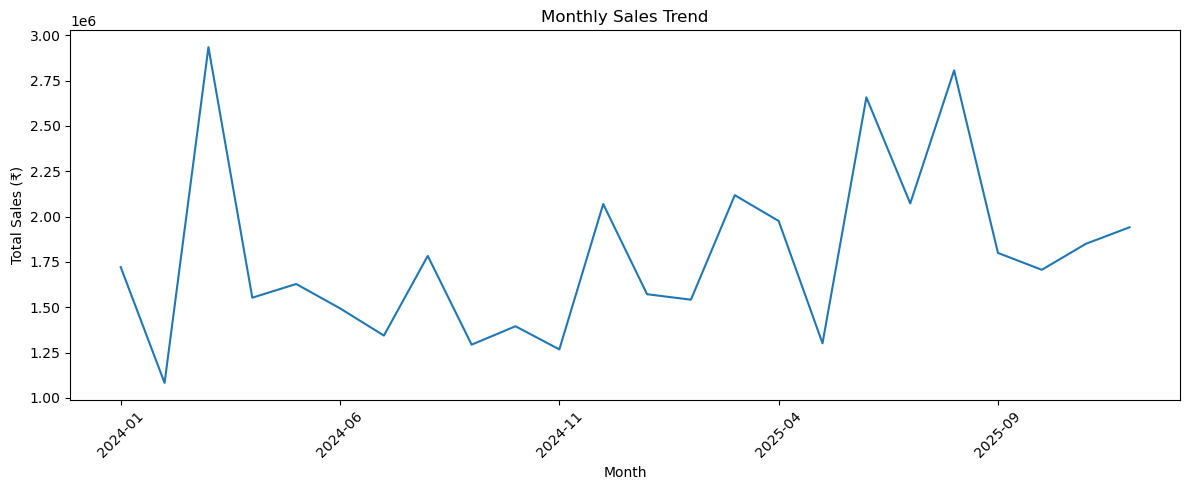

In [ ]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Order_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_analysis = df.groupby("Order_Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

monthly_analysis.plot(
    y="Total_Sales",
    figsize=(12, 5),
    title="Monthly Sales Trend",
    legend=False
)

plt.ylabel("Total Sales (₹)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(df.columns.tolist())


*Does giving higher discounts reduce profitability?*


In [ ]:
discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Order_Count=("Order_ID", "nunique")
)

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"]
) * 100

discount_analysis

,Total_Sales,Total_Profit,Order_Count,Profit_Margin_%
Discount,,,,
0.00,9833492.16,2468822.25,456,25.106261
0.05,11089414.53,2381335.80,589,21.473954
0.10,10665515.16,1909382.19,691,17.902391
0.15,6323457.98,782216.52,408,12.370075
0.20,3523553.46,266140.78,242,7.553193
0.25,1327861.40,26750.60,109,2.014563


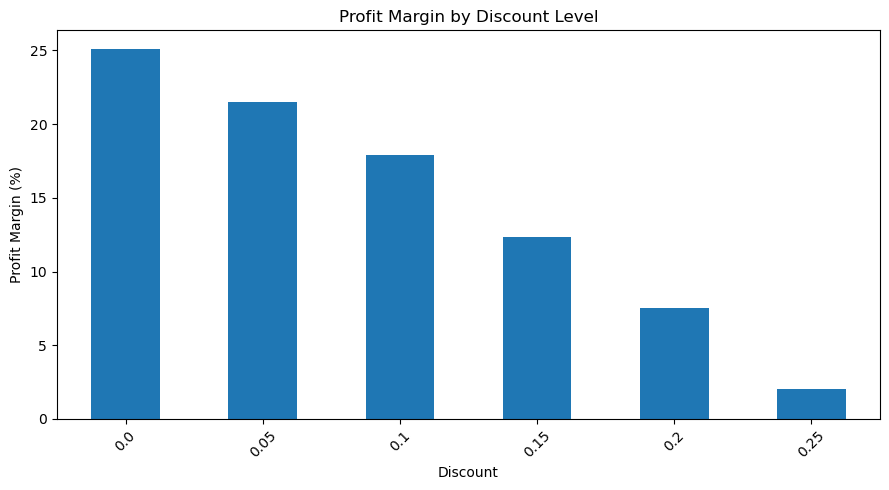

In [ ]:
discount_analysis["Profit_Margin_%"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Profit Margin by Discount Level"
)

plt.xlabel("Discount")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
%pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import mysql.connector
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Sahil@13",
    database="ecommerce_ai"
)
print("Connected successfully!")

Connected successfully!


In [ ]:
import pandas as pd

In [ ]:
query = """
SELECT
    Category,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM ecommerce_sales_ai_agent_dataset
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

category_df = pd.read_sql(query, conn)

display(category_df)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\3259951028.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  category_df = pd.read_sql(query, conn)


,Category,Total_Sales,Total_Profit
0,Electronics,32511354.29,4694895.66
1,Home & Kitchen,5794498.27,1540681.71
2,Fashion,2205127.46,779107.34
3,Sports,1506630.06,484435.65
4,Beauty,840278.89,356068.51


In [ ]:
query = """
SELECT
    Product,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM ecommerce_sales_ai_agent_dataset
GROUP BY Product
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_products_df = pd.read_sql(query, conn)

display(top_products_df)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\1329381958.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_products_df = pd.read_sql(query, conn)


,Product,Total_Sales,Total_Profit
0,Laptop,16386152.09,2456497.46
1,Smartphone,8533214.15,1176780.03
2,Tablet,5111665.70,710337.87
3,Vacuum Cleaner,2084773.39,576825.34
4,Smartwatch,1607546.41,235571.91
5,Air Fryer,1036680.70,263405.11
6,Coffee Maker,1018425.00,266414.51
7,Headphones,872775.94,115708.39
8,Cookware Set,841299.94,221855.23
9,Mixer Grinder,813319.24,212181.52


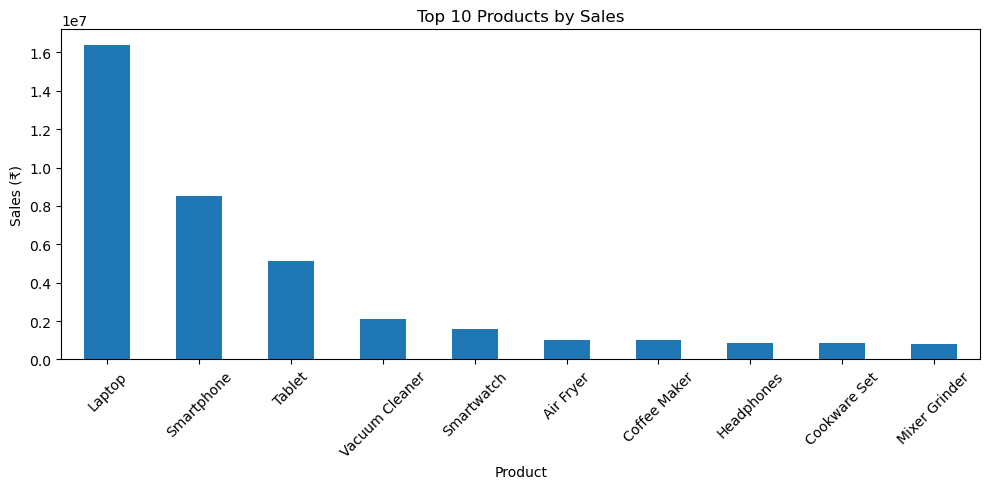

In [ ]:
import matplotlib.pyplot as plt

top_products_df.plot(
    x="Product",
    y="Total_Sales",
    kind="bar",
    figsize=(10, 5),
    legend=False,
    title="Top 10 Products by Sales"
)

plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
def run_sql_query(query):
    try:
        result = pd.read_sql(query, conn)
        return result
    except Exception as e:
        print("Query failed:", e)
        return None

In [ ]:
query = """
SELECT
    Region,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM ecommerce_sales_ai_agent_dataset
GROUP BY Region
ORDER BY Total_Sales DESC;
"""

region_df = run_sql_query(query)

display(region_df)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Region,Total_Sales,Total_Profit
0,South,11463003.39,2112839.46
1,West,9409468.77,1741212.07
2,Central,7884853.45,1380398.35
3,North,7319259.59,1392410.01
4,East,6781303.77,1228328.98


In [ ]:
query = """
SELECT
    Customer_ID,
    COUNT(DISTINCT Order_ID) AS Total_Orders,
    ROUND(SUM(Sales), 2) AS Total_Sales
FROM ecommerce_sales_ai_agent_dataset
GROUP BY Customer_ID
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_customers_df = run_sql_query(query)

display(top_customers_df)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Customer_ID,Total_Orders,Total_Sales
0,CUST00592,4,549007.39
1,CUST00304,7,422562.64
2,CUST00161,6,366119.58
3,CUST00753,6,358864.64
4,CUST00688,5,343547.43
5,CUST00420,6,342642.47
6,CUST00332,2,310896.38
7,CUST00301,5,300845.82
8,CUST00059,5,298239.56
9,CUST00714,3,285443.03


In [ ]:
def answer_business_question(question):
    question = question.lower()

    if "region" in question and "sales" in question:
        query = """
        SELECT Region,
               ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Region
        ORDER BY Total_Sales DESC;
        """

    elif "category" in question and "profit" in question:
        query = """
        SELECT Category,
               ROUND(SUM(Profit), 2) AS Total_Profit
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Category
        ORDER BY Total_Profit DESC;
        """

    elif "top" in question and "product" in question:
        query = """
        SELECT Product,
               ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Product
        ORDER BY Total_Sales DESC
        LIMIT 10;
        """

    else:
        return "Sorry, I don't understand that question yet."

    return run_sql_query(query)

In [ ]:
answer_business_question(
    "Which region generates the highest sales?"
)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Region,Total_Sales
0,South,11463003.39
1,West,9409468.77
2,Central,7884853.45
3,North,7319259.59
4,East,6781303.77


In [ ]:
answer_business_question(
    "Which category generates the highest profit?"
)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Category,Total_Profit
0,Electronics,4694895.66
1,Home & Kitchen,1540681.71
2,Fashion,779107.34
3,Sports,484435.65
4,Beauty,356068.51


In [ ]:
answer_business_question(
    "Show me the top products"
)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Product,Total_Sales
0,Laptop,16386152.09
1,Smartphone,8533214.15
2,Tablet,5111665.70
3,Vacuum Cleaner,2084773.39
4,Smartwatch,1607546.41
5,Air Fryer,1036680.70
6,Coffee Maker,1018425.00
7,Headphones,872775.94
8,Cookware Set,841299.94
9,Mixer Grinder,813319.24


In [ ]:
def generate_business_insight(result, metric, group_name):
    if result is None or result.empty:
        return "No results found."

    best_row = result.loc[result[metric].idxmax()]

    print(f"Top performer: {best_row[group_name]}")
    print(f"{metric}: ₹{best_row[metric]:,.2f}")

    return best_row

In [ ]:
region_df = answer_business_question(
    "Which region generates the highest sales?"
)

generate_business_insight(
    region_df,
    metric="Total_Sales",
    group_name="Region"
)

Top performer: South
Total_Sales: ₹11,463,003.39


C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


Region               South
Total_Sales    11463003.39
Name: 0, dtype: object

In [ ]:
profit_df = answer_business_question(
    "Which category generates the highest profit?"
)

generate_business_insight(
    profit_df,
    metric="Total_Profit",
    group_name="Category"
)

Top performer: Electronics
Total_Profit: ₹4,694,895.66


C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


Category        Electronics
Total_Profit     4694895.66
Name: 0, dtype: object

In [ ]:
questions = [
    "Which region generates the highest sales?",
    "Which category generates the highest profit?",
    "Show me the top products"
]

for question in questions:
    print("\nQuestion:", question)
    result = answer_business_question(question)
    display(result)


Question: Which region generates the highest sales?


C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Region,Total_Sales
0,South,11463003.39
1,West,9409468.77
2,Central,7884853.45
3,North,7319259.59
4,East,6781303.77



Question: Which category generates the highest profit?


C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Category,Total_Profit
0,Electronics,4694895.66
1,Home & Kitchen,1540681.71
2,Fashion,779107.34
3,Sports,484435.65
4,Beauty,356068.51



Question: Show me the top products


C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Product,Total_Sales
0,Laptop,16386152.09
1,Smartphone,8533214.15
2,Tablet,5111665.70
3,Vacuum Cleaner,2084773.39
4,Smartwatch,1607546.41
5,Air Fryer,1036680.70
6,Coffee Maker,1018425.00
7,Headphones,872775.94
8,Cookware Set,841299.94
9,Mixer Grinder,813319.24


In [ ]:
models = client.models.list()

for model in models.data:
    print(model.id)

NameError: name 'client' is not defined

In [ ]:
from groq import Groq
import os

In [ ]:
client = Groq(api_key=groq_api_key)

print("Groq client initialized successfully!")

Groq client initialized successfully!


In [58]:
models = client.models.list()

for model in models.data:
    print(model.id)

meta-llama/llama-prompt-guard-2-86m
allam-2-7b
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
canopylabs/orpheus-arabic-saudi
openai/gpt-oss-safeguard-20b
whisper-large-v3-turbo
qwen/qwen3.8-27b
whisper-large-v3
openai/gpt-oss-20b
openai/gpt-oss-120b


In [59]:
response = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[
        {
            "role": "user",
            "content": "Explain total sales in one simple sentence."
        }
    ],
    temperature=0.2
)

print(response.choices[0].message.content)

Total sales is the sum of all revenue earned from selling products or services during a specific period.


In [60]:
query = """
SELECT Category,
       ROUND(SUM(Sales), 2) AS Total_Sales,
       ROUND(SUM(Profit), 2) AS Total_Profit
FROM ecommerce_sales_ai_agent_dataset
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

category_df = run_sql_query(query)
display(category_df)

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Category,Total_Sales,Total_Profit
0,Electronics,32511354.29,4694895.66
1,Home & Kitchen,5794498.27,1540681.71
2,Fashion,2205127.46,779107.34
3,Sports,1506630.06,484435.65
4,Beauty,840278.89,356068.51


In [61]:
data = category_df.to_string(index=False)

prompt = f"""
You are an e-commerce business data analyst.

Analyze the following sales and profit data by product category.

Data:
{data}

Explain:
1. Which category has the highest sales?
2. Which category has the highest profit?
3. What business insight can we learn from this data?

Use simple language and only use the provided data.
"""

response = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[
        {
            "role": "user",
            "content": prompt
        }
    ],
    temperature=0.2
)

print(response.choices[0].message.content)

**1. Highest sales**  
- **Electronics** – $32,511,354.29 is the largest sales figure among all categories.

**2. Highest profit**  
- **Electronics** – $4,694,895.66 is the largest profit figure among all categories.

**3. Business insight**  
- Electronics is the clear leader: it brings in the most money and also earns the most profit.  
- The other categories (Home & Kitchen, Fashion, Sports, Beauty) generate far less sales and profit.  
- This suggests that the business should keep investing in electronics—whether that means more marketing, better inventory, or improved customer service—because it is the most profitable part of the store.  
- If the goal is to grow overall revenue, focusing on the categories that are currently lower (especially Home & Kitchen and Fashion) could also be a strategy, but the data shows electronics is the strongest performer right now.


In [62]:
print("SQL connection:", conn.is_connected())
print("SQL function:", callable(run_sql_query))
print("Groq client:", client is not None)

SQL connection: True
SQL function: True
Groq client: True


In [63]:

def ask_ai_about_data(question, sql_results):
    if sql_results is None or sql_results.empty:
        return "No data found for this question."

    data = sql_results.to_string(index=False)

    prompt = f"""
    You are an e-commerce sales data analyst.

    User question: {question}

    SQL query results:
    {data}

    Answer the user's question using only the supplied data.
    Explain the key finding clearly and concisely.
    Include relevant figures when available.
    Do not invent facts or make unsupported claims.
    """

    response = client.chat.completions.create(
        model="openai/gpt-oss-20b",
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


In [64]:
answer = ask_ai_about_data(
    "Which category has the highest sales and why?",
    category_df
)

print(answer)

**Highest‑selling category**

| Category | Total Sales | Total Profit |
|----------|-------------|--------------|
| **Electronics** | **$32,511,354.29** | **$4,694,895.66** |

**Key finding**

- **Electronics** leads all categories in revenue, with sales of $32.5 million, far exceeding the next highest category (Home & Kitchen at $5.8 million).  
- It also generates the largest profit ($4.7 million), suggesting that the high sales volume is accompanied by a healthy margin.

**Why it stands out**

- The data show that the electronics category not only pulls in the most revenue but also converts that revenue into the greatest profit. This combination indicates that the category is both popular with customers and financially efficient for the business.


In [65]:

def ask_business_question(question):
    question_lower = question.lower()

    if "region" in question_lower and "sales" in question_lower:
        query = """
        SELECT Region,
               ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Region
        ORDER BY Total_Sales DESC;
        """

    elif "category" in question_lower and "profit" in question_lower:
        query = """
        SELECT Category,
               ROUND(SUM(Profit), 2) AS Total_Profit
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Category
        ORDER BY Total_Profit DESC;
        """

    elif "top" in question_lower and "product" in question_lower:
        query = """
        SELECT Product,
               ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Product
        ORDER BY Total_Sales DESC
        LIMIT 10;
        """

    else:
        return (
            "This question is not supported yet. "
            "Try asking about regional sales, category profit, "
            "or top products by sales."
        )

    result = run_sql_query(query)

    if result is None or result.empty:
        return "No results found."

    return ask_ai_about_data(question, result)


In [66]:
print(ask_business_question("Which region has the highest sales?"))

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


**Answer:**  
The **South** region has the highest sales.

**Key finding:**  
- South: **$11,463,003.39**  
- West: $9,409,468.77  
- Central: $7,884,853.45  
- North: $7,319,259.59  
- East: $6,781,303.77  

Thus, the South region leads by a margin of over $2 million compared to the next highest region (West).


In [67]:
print(ask_business_question(
    "Which category has the highest profit?"
))

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


**Answer:**  
The category with the highest profit is **Electronics**, with a total profit of **$4,694,895.66**.

**Key finding:**  
- Electronics outperforms all other categories by a substantial margin, earning roughly **$3.2 million more** than the next highest category (Home & Kitchen).


In [68]:
print(ask_business_question(
    "Show the top 10 products by sales."
))

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


**Top 10 Products by Total Sales**

| Rank | Product          | Total Sales (USD) |
|------|------------------|-------------------|
| 1    | Laptop           | 16,386,152.09 |
| 2    | Smartphone       | 8,533,214.15 |
| 3    | Tablet           | 5,111,665.70 |
| 4    | Vacuum Cleaner   | 2,084,773.39 |
| 5    | Smartwatch       | 1,607,546.41 |
| 6    | Air Fryer        | 1,036,680.70 |
| 7    | Coffee Maker     | 1,018,425.00 |
| 8    | Headphones       | 872,775.94 |
| 9    | Cookware Set     | 841,299.94 |
| 10   | Mixer Grinder    | 813,319.24 |

**Key Finding**

- **Laptop sales dominate** the portfolio, generating over **$16.4 million**—nearly twice the sales of the second‑ranked product (Smartphone).  
- The top three products (Laptop, Smartphone, Tablet) together account for **~$30 million** in revenue, representing a substantial portion of overall sales.  
- The remaining seven products contribute a smaller, but still significant, share, with the lowest‑ranking product (Mixer

In [69]:

def ask_business_question(question):
    q = question.lower()

    if any(word in q for word in ["region", "regional"]) and \
       any(word in q for word in ["sales", "revenue"]):

        query = """
        SELECT Region,
               ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Region
        ORDER BY Total_Sales DESC;
        """

    elif any(word in q for word in ["category", "categories"]) and \
         any(word in q for word in ["profit", "profitable"]):

        query = """
        SELECT Category,
               ROUND(SUM(Profit), 2) AS Total_Profit
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Category
        ORDER BY Total_Profit DESC;
        """

    elif any(word in q for word in ["product", "products"]) and \
         any(word in q for word in ["top", "best", "highest", "sales"]):

        query = """
        SELECT Product,
               ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Product
        ORDER BY Total_Sales DESC
        LIMIT 10;
        """

    else:
        return (
            "Question not supported yet. Try asking about "
            "regional sales, category profit, or top products."
        )

    result = run_sql_query(query)

    if result is None or result.empty:
        return "No results found."

    return ask_ai_about_data(question, result)


In [70]:
print(ask_business_question("Which region generates the most revenue?"))

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


**Answer:**  
The **South** region generates the most revenue.

**Key finding:**  
- South: **$11,463,003.39**  
- West: $9,409,468.77  
- Central: $7,884,853.45  
- North: $7,319,259.59  
- East: $6,781,303.77  

Thus, the South region leads by a margin of over $2 million compared to the next highest region (West).


C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


,Total_Sales,Total_Profit,Profit_Margin_Percent
0,42857888.97,7855188.87,18.33


In [72]:

def ask_business_question(question):
    q = question.lower()

    if any(word in q for word in ["overall", "total", "summary", "margin"]) and \
       any(word in q for word in ["sales", "profit", "business", "margin", "summary"]):

        query = """
        SELECT
            ROUND(SUM(Sales), 2) AS Total_Sales,
            ROUND(SUM(Profit), 2) AS Total_Profit,
            ROUND(SUM(Profit) / NULLIF(SUM(Sales), 0) * 100, 2)
                AS Profit_Margin_Percent
        FROM ecommerce_sales_ai_agent_dataset;
        """

    elif any(word in q for word in ["region", "regional"]) and \
         any(word in q for word in ["sales", "revenue"]):

        query = """
        SELECT Region, ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Region ORDER BY Total_Sales DESC;
        """

    elif any(word in q for word in ["category", "categories"]) and \
         any(word in q for word in ["profit", "profitable"]):

        query = """
        SELECT Category, ROUND(SUM(Profit), 2) AS Total_Profit
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Category ORDER BY Total_Profit DESC;
        """

    elif any(word in q for word in ["product", "products"]) and \
         any(word in q for word in ["top", "best", "highest", "sales"]):

        query = """
        SELECT Product, ROUND(SUM(Sales), 2) AS Total_Sales
        FROM ecommerce_sales_ai_agent_dataset
        GROUP BY Product ORDER BY Total_Sales DESC LIMIT 10;
        """

    else:
        return (
            "Question not supported yet. Try asking about overall business "
            "summary, regional sales, category profit, or top products."
        )

    result = run_sql_query(query)

    if result is None or result.empty:
        return "No results found."

    return ask_ai_about_data(question, result)


In [73]:
print(ask_business_question("Give me an overall business summary"))

C:\Users\unnat\AppData\Local\Temp\ipykernel_19164\4234572625.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql(query, conn)


**Overall Business Summary**

- **Total Sales:** $42,857,888.97  
- **Total Profit:** $7,855,188.87  
- **Profit Margin:** 18.33 %

**Key Finding:**  
The business generated nearly $43 million in sales and achieved a profit margin of 18.33 %. This margin indicates that for every dollar of revenue, about 18 cents are retained as profit, reflecting a solid profitability level for the period covered.


In [74]:
print(
    ask_business_question(
        "What is the weather today?"
    )
)

Question not supported yet. Try asking about overall business summary, regional sales, category profit, or top products.


In [75]:
%pip install streamlit sqlalchemy

Note: you may need to restart the kernel to use updated packages.
